<a href="https://colab.research.google.com/github/SithmiDesilva/Voices-on-School-Reform-An-NLP-Analysis-of-Sri-Lankan-YouTube-Comments/blob/Data-collection-and-EDA/Voices_on_School_Reform_An_NLP_Analysis_of_Sri_Lankan_YouTube_Comments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Imports and Versions

In [110]:
import os, re, json, time, random, hashlib, math
from datetime import datetime, timezone
from pathlib import Path
from collections import Counter
from importlib.metadata import version
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

SEED = 42
random.seed(SEED); np.random.seed(SEED)

pd.set_option('display.max_colwidth', 120)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

print('Python                  ', sys.version.split()[0])
print('pandas                  ', pd.__version__)
print('numpy                   ', np.__version__)
print('matplotlib              ', matplotlib.__version__)
print('scikit-learn            ', sklearn.__version__)
print('google-api-python-client', version('google-api-python-client'))

Python                   3.13.16
pandas                   2.2.3
numpy                    2.4.6
matplotlib               3.10.0
scikit-learn             1.6.1
google-api-python-client 2.201.0


### Mount Google drive

In [111]:
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = Path('/content/drive/MyDrive/NLP_CW')
RAW_DIR  = BASE_DIR / 'data' / 'raw'
CKPT_DIR = RAW_DIR / 'comments_by_video'      # one JSON per video (checkpoint)
FIG_DIR  = BASE_DIR / 'figures'
for d in (RAW_DIR, CKPT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print(BASE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/NLP_CW


### API client

In [112]:
from google.colab import userdata
YT_API_KEY = userdata.get('YT_API_KEY')
youtube = build('youtube', 'v3', developerKey=YT_API_KEY, cache_discovery=False)

try:
    AUTHOR_SALT = userdata.get('AUTHOR_SALT')
except Exception:
    AUTHOR_SALT = 'change-me-and-store-in-secrets'
print('YouTube client ready')

YouTube client ready


### Search queries and settings

In [113]:
SEARCH_QUERIES = {
    'en': [
        'Sri Lanka education reform',
        'Sri Lanka new education reforms 2026',
        'Sri Lanka school curriculum change',
        'Sri Lanka O/L A/L exam reform',
        'Sri Lanka grade 1 grade 6 new curriculum',
        'Sri Lanka education reform teachers',
        'Sri Lanka modular education system school',
        'Sri Lanka vocational education schools reform',
        'Sri Lanka digital education schools',
        'Sri Lanka history subject removed curriculum',
        'Sri Lanka education minister reform debate',
    ],
    'si': [
        'අධ්‍යාපන ප්‍රතිසංස්කරණ',
        'නව අධ්‍යාපන ප්‍රතිසංස්කරණ',
        'අධ්‍යාපන ප්‍රතිසංස්කරණ ගුරුවරු',
        'නව විෂය නිර්දේශය පාසල්',
        'සාමාන්‍ය පෙළ උසස් පෙළ වෙනස්කම්',
        '6 ශ්‍රේණිය මොඩියුල',
        'පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ',
        'adyapana prathisanskarana',       # romanised Sinhala ("Singlish")
    ],
}

PUBLISHED_AFTER = '2024-01-01T00:00:00Z'   # current reform cycle
REGION_CODE = 'LK'
RESULTS_PER_QUERY = 25          # max 50 per search call
MIN_COMMENT_COUNT = 15          # skip videos with very few comments
MAX_COMMENTS_PER_VIDEO = 800    # per-video ceiling (30% rule applied later)
INCLUDE_REPLIES = True
FETCH_ALL_REPLIES = True        # commentThreads gives only 5 inline replies; fetch the rest
COMMENT_ORDER = 'time'          # avoids YouTube's relevance ranking
MAX_VIDEO_SHARE = 0.30
TARGET_MIN_COMMENTS = 3000

RELEVANCE_KEYWORDS = [
    'education', 'reform', 'curriculum', 'syllabus', 'school', 'exam', 'o/l', 'a/l', 'grade', 'teacher',
    'module', 'vocational', 'student',
    'අධ්‍යාපන', 'ප්‍රතිසංස්කරණ', 'විෂය', 'පාසල', 'ගුරු', 'ශ්‍රේණිය', 'පෙළ', 'විභාග', 'මොඩියුල', 'සිසු',
]
SRI_LANKA_KEYWORDS = ['sri lanka', 'srilanka', 'lanka', 'ශ්‍රී ලංකා', 'ලංකා', 'harini', 'හරිනි']

COLLECTION_DATE = datetime.now(timezone.utc).isoformat()
print('Total queries:', sum(len(v) for v in SEARCH_QUERIES.values()))

Total queries: 19


### Quota-aware API wrapper

In [114]:
QUOTA_COST = {'search': 100, 'videos': 1, 'commentThreads': 1, 'comments': 1}
quota_used = Counter()

class QuotaExceeded(Exception):
    pass

def http_reason(e):
    try:
        return json.loads(e.content.decode())['error']['errors'][0]['reason']
    except Exception:
        return f'http_{getattr(e.resp, "status", "unknown")}'

def api_call(request, kind, max_retries=4):
    for attempt in range(max_retries):
        try:
            resp = request.execute()
            quota_used[kind] += QUOTA_COST[kind]
            return resp
        except HttpError as e:
            quota_used[kind] += QUOTA_COST[kind]
            reason = http_reason(e)
            if reason in ('quotaExceeded', 'dailyLimitExceeded'):
                raise QuotaExceeded(reason)
            if e.resp.status in (500, 502, 503, 504) and attempt < max_retries - 1:
                time.sleep(2 ** attempt)
                continue
            raise

def quota_total():
    return sum(quota_used.values())

### Search for videos (results cached to Drive)

In [115]:
SEARCH_CACHE = RAW_DIR / 'search_cache.json'
search_cache = json.loads(SEARCH_CACHE.read_text()) if SEARCH_CACHE.exists() else {}

def search_videos(query, lang):
    key = f'{lang}|{query}'
    if key in search_cache:
        return search_cache[key]
    req = youtube.search().list(
        q=query, part='snippet', type='video', maxResults=min(RESULTS_PER_QUERY, 50),
        regionCode=REGION_CODE, relevanceLanguage=lang,
        publishedAfter=PUBLISHED_AFTER, order='relevance')
    resp = api_call(req, 'search')
    rows = [{
        'query': query, 'query_lang': lang,
        'video_id': it['id']['videoId'],
        'title': it['snippet']['title'],
        'channel_id': it['snippet']['channelId'],
        'channel_title': it['snippet']['channelTitle'],
        'video_published_at': it['snippet']['publishedAt'],
        'searched_at': datetime.now(timezone.utc).isoformat(),
    } for it in resp.get('items', [])]
    search_cache[key] = rows
    SEARCH_CACHE.write_text(json.dumps(search_cache, ensure_ascii=False, indent=1))
    return rows

hits = []
for lang, queries in SEARCH_QUERIES.items():
    for q in queries:
        hits.extend(search_videos(q, lang))

search_df = pd.DataFrame(hits)
print(f'{len(search_df)} hits, {search_df.video_id.nunique()} unique videos, quota used: {quota_total()}')
search_df.groupby('query_lang').video_id.nunique()

475 hits, 306 unique videos, quota used: 0


,video_id
query_lang,
en,197
si,121


### Video details (comment counts, descriptions)


In [116]:
cand = (search_df.groupby('video_id')
        .agg(title=('title', 'first'), channel_id=('channel_id', 'first'),
             channel_title=('channel_title', 'first'), video_published_at=('video_published_at', 'first'),
             matched_queries=('query', lambda s: ' || '.join(sorted(set(s)))),
             query_langs=('query_lang', lambda s: ','.join(sorted(set(s)))))
        .reset_index())

details = []
ids = cand.video_id.tolist()
for i in range(0, len(ids), 50):
    resp = api_call(youtube.videos().list(part='snippet,statistics', id=','.join(ids[i:i+50])), 'videos')
    for it in resp.get('items', []):
        st, sn = it.get('statistics', {}), it['snippet']
        details.append({
            'video_id': it['id'],
            'description': sn.get('description', ''),
            'tags': '|'.join(sn.get('tags', [])),
            'default_audio_language': sn.get('defaultAudioLanguage'),
            'view_count': int(st.get('viewCount', 0)),
            'comment_count': int(st['commentCount']) if 'commentCount' in st else None,  # missing = disabled
        })
videos = cand.merge(pd.DataFrame(details), on='video_id', how='left')
print('Videos with comments disabled/unavailable:', videos.comment_count.isna().sum())

Videos with comments disabled/unavailable: 11


### Relevance filter and manual review

In [117]:
def kw_hits(text, kws):
    t = str(text).lower()
    return sum(k.lower() in t for k in kws)

meta_text = videos.title.fillna('') + ' ' + videos.description.fillna('') + ' ' + videos.tags.fillna('')
videos['topic_kw_hits'] = meta_text.apply(lambda t: kw_hits(t, RELEVANCE_KEYWORDS))
videos['lk_kw_hits'] = meta_text.apply(lambda t: kw_hits(t, SRI_LANKA_KEYWORDS))
videos['local_query'] = videos.query_langs.str.contains('si')

videos['exclusion_reason'] = np.select(
    [videos.comment_count.isna(),
     videos.comment_count < MIN_COMMENT_COUNT,
     videos.topic_kw_hits == 0,
     (videos.lk_kw_hits == 0) & ~videos.local_query],
    ['comments_disabled_or_unavailable', 'too_few_comments', 'no_topic_keywords', 'not_sri_lanka'],
    default='')
videos['auto_include'] = videos.exclusion_reason == ''

# ---- Manual review: fill in after reading the titles below ----
MANUAL_EXCLUDE = {'4ii1rkZDhgI': 'geography/identity topic, not school reform'}   # {'videoId': 'reason'}
MANUAL_INCLUDE = {}   # {'videoId': 'reason'}
# ---------------------------------------------------------------
videos['include'] = videos.auto_include
for vid, why in MANUAL_EXCLUDE.items():
    videos.loc[videos.video_id == vid, ['include', 'exclusion_reason']] = [False, f'manual: {why}']
for vid, why in MANUAL_INCLUDE.items():
    videos.loc[videos.video_id == vid, ['include', 'exclusion_reason']] = [True, f'manual include: {why}']

videos.to_csv(RAW_DIR / 'videos_candidates.csv', index=False)
print(videos.exclusion_reason.replace('', 'included').value_counts(), '')
print('Included videos:', videos.include.sum(), '| channels:', videos.loc[videos.include, 'channel_id'].nunique())
videos.loc[videos.include, ['video_id', 'channel_title', 'title', 'comment_count', 'video_published_at']] \
      .sort_values('comment_count', ascending=False)

exclusion_reason
too_few_comments                                       195
included                                                72
not_sri_lanka                                           18
comments_disabled_or_unavailable                        11
no_topic_keywords                                        9
manual: geography/identity topic, not school reform      1
Name: count, dtype: int64 
Included videos: 72 | channels: 55


,video_id,channel_title,title,comment_count,video_published_at
234,h9nL4RwNAEE,Truth With Sama,ශ්‍රී ලංකාවේ හොදම පාසල් 10 😱 | Top 10 best school in the srilanka #truthwithsama #top10 #viral,2497.0,2024-05-29T10:14:08Z
75,F-DLnJM7jpg,Ada Derana,"O/L, A/L සහ ශිෂ්‍යත්ව විභාගය ගැන දැනුම්දීමක් | Ada Derana",1030.0,2026-06-24T10:37:50Z
141,RHfwHM3M9Fc,Ada Derana,අධ්‍යාපන ප්‍රතිසංස්කරණ ඇත්තටම අකුල ගත්තේ ඇයි | Ada Derana,845.0,2026-01-13T19:27:31Z
14,1mGozsjkLYQ,Maths Crew,How to do AL private | Private AL Apply | උසස් පෙළ විභාගයට private apply කරන්නෙ කොහොමද ?,768.0,2025-01-19T13:00:02Z
4,-pHFRz2p-Nw,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,728.0,2025-07-18T12:33:39Z
...,...,...,...,...,...
205,aawhznhUzpU,Lanka Prasad,2026 Grade 6| මොඩියුලර් | Day 2,17.0,2025-10-30T04:15:05Z
35,5rkNywVfrTU,WION,Sri Lanka Delays Grade 6 Reforms After Adult Website Link Found In Textbook | WION,16.0,2026-01-15T04:09:49Z
170,W32WN3WT_i8,Sri Lankan YouTube School,Familiarizing 2026 Grade 6 English New Curriculum Reforms TG,16.0,2025-11-23T12:30:44Z
268,ovjGS5qae5Y,Shakthi FM,Only 7 subjects for O/L from now on? | Massive change in Sri Lanka&#39;s education system! 🚨 Shakthi FM,16.0,2026-09-15T09:28:53Z


### Comment-fetching functions

In [118]:
def hash_author(channel_id):
    if not channel_id:
        return None
    return hashlib.sha256((AUTHOR_SALT + channel_id).encode()).hexdigest()[:16]

def make_row(c, video_id, is_reply, parent_id):
    s = c['snippet']
    return {
        'comment_id': c['id'],
        'parent_id': parent_id,
        'is_reply': is_reply,
        'video_id': video_id,
        'text_original': s.get('textOriginal', s.get('textDisplay')),
        'like_count': s.get('likeCount'),
        'comment_published_at': s.get('publishedAt'),
        'comment_updated_at': s.get('updatedAt'),
        'author_hash': hash_author(s.get('authorChannelId', {}).get('value')),  # no names stored
    }

def fetch_all_replies(parent_id, video_id):
    out, token = [], None
    while True:
        resp = api_call(youtube.comments().list(part='snippet', parentId=parent_id, maxResults=100,
                                                pageToken=token, textFormat='plainText'), 'comments')
        out += [make_row(r, video_id, True, parent_id) for r in resp.get('items', [])]
        token = resp.get('nextPageToken')
        if not token:
            return out

def fetch_video_comments(video_id, max_comments=MAX_COMMENTS_PER_VIDEO):
    rows, token = [], None
    while len(rows) < max_comments:
        try:
            resp = api_call(youtube.commentThreads().list(
                part='snippet,replies', videoId=video_id, maxResults=100, pageToken=token,
                textFormat='plainText', order=COMMENT_ORDER), 'commentThreads')
        except HttpError as e:
            return rows, http_reason(e)      # e.g. commentsDisabled
        for item in resp.get('items', []):
            top = item['snippet']['topLevelComment']
            rows.append(make_row(top, video_id, False, None))
            n_rep = item['snippet'].get('totalReplyCount', 0)
            if INCLUDE_REPLIES and n_rep:
                inline = item.get('replies', {}).get('comments', [])
                if FETCH_ALL_REPLIES and n_rep > len(inline):
                    rows += fetch_all_replies(top['id'], video_id)
                else:
                    rows += [make_row(r, video_id, True, top['id']) for r in inline]
        token = resp.get('nextPageToken')
        if not token:
            break
    return rows, 'ok'

### Collect comments (resumable)

In [119]:
selected = videos[videos.include].sort_values('comment_count', ascending=False)
status_log = {}

try:
    for _, v in selected.iterrows():
        ck = CKPT_DIR / f'{v.video_id}.json'
        if ck.exists():
            status_log[v.video_id] = json.loads(ck.read_text())['status']
            continue
        rows, status = fetch_video_comments(v.video_id)
        ck.write_text(json.dumps({'video_id': v.video_id, 'status': status,
                                  'collected_at': datetime.now(timezone.utc).isoformat(),
                                  'comments': rows}, ensure_ascii=False))
        status_log[v.video_id] = status
        print(f'{v.video_id}  {status:<18} {len(rows):>5} comments   quota used: {quota_total()}')
except QuotaExceeded:
    print('Daily quota reached; checkpoints saved. Re-run this cell tomorrow to resume.')

print('Quota used this session:', dict(quota_used), '=', quota_total())

Quota used this session: {'videos': 7} = 7


### Save the unmodified raw file

In [120]:
records = []
for ck in sorted(CKPT_DIR.glob('*.json')):
    d = json.loads(ck.read_text())
    for r in d['comments']:
        r['collected_at'] = d['collected_at']
        records.append(r)

raw = pd.DataFrame(records)
vid_meta = videos[['video_id', 'channel_id', 'channel_title', 'title', 'video_published_at', 'matched_queries']] \
           .rename(columns={'title': 'video_title'})
raw = raw.merge(vid_meta, on='video_id', how='left')
raw.to_csv(RAW_DIR / 'raw_comments.csv', index=False, encoding='utf-8-sig')   # never edited after this
print(raw.shape)
raw.head(500)

(12810, 15)


,comment_id,parent_id,is_reply,video_id,text_original,like_count,comment_published_at,comment_updated_at,author_hash,collected_at,channel_id,channel_title,video_title,video_published_at,matched_queries
0,UgxzwPiB2TauS3ZJNNZ4AaABAg,None,False,-0pCTULWg8g,Ane Teecha Dan barida ape babawa danna,0,2026-11-04T10:39:42Z,2026-11-04T10:39:42Z,1692ab2fb2c9c7dc,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
1,UgyfsK0A8bV52nudHHV4AaABAg,None,False,-0pCTULWg8g,Teacher ape baba 1 sereniye teacher clz ekata sambanda karaganna puluwanda,0,2026-10-29T02:41:36Z,2026-10-29T02:41:36Z,76cd7dd46cf7faf5,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
2,Ugx4-snGmG-yERJVvKV4AaABAg,None,False,-0pCTULWg8g,අපේ පුතාවත් සම්බන්ධ කරන්න කැමතියි ටීචර් ඔයා හරිම ලස්සනට උගන්වනවා තෙරුවන් සරණයි ටිච,0,2026-10-11T16:30:22Z,2026-10-11T16:30:22Z,c9ff2a64dfd4901a,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
3,UgzThGekDYmgBZe8lTB4AaABAg,None,False,-0pCTULWg8g,මේ ළමයින්ට මොන පන්තිද,1,2026-06-17T10:17:55Z,2026-06-17T10:17:55Z,daeb4003ebc0ebb7,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
4,UgzHRJI41skEsejDuOl4AaABAg,None,False,-0pCTULWg8g,ටිච ක්ලාස් එකට ජොයින් වෙින්න ඔනි.කොහොමද ?,1,2026-06-10T11:02:36Z,2026-06-10T11:02:36Z,6d67588bb5466981,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,Ugw6ftyK1VTVkBs53Wx4AaABAg,None,False,-pHFRz2p-Nw,තෝරගන්න විෂයන් ඇතුළෙ අනිවාර්ය කරන්න ඕන ඒව තියෙනවා සිංහල ආගම අයින් කරල IT අනිවාර්ය කරන්න තිබ්බෙ,1,2025-07-19T12:59:53Z,2025-07-19T12:59:53Z,3d324362f32d8540,2026-11-20T09:17:05.223558+00:00,UC_0nRvlMjooFAZEiMTkCglA,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,2025-07-18T12:33:39Z,නව විෂය නිර්දේශය පාසල්
496,Ugy78Su5UDXhUqG9RQV4AaABAg,None,False,-pHFRz2p-Nw,සෞන්දර්ය විෂය ඇතුලේ රසාස්වාදය තියෙයි ද ?,1,2025-07-19T12:56:03Z,2025-07-19T12:56:03Z,d34994a7407eb263,2026-11-20T09:17:05.223558+00:00,UC_0nRvlMjooFAZEiMTkCglA,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,2025-07-18T12:33:39Z,නව විෂය නිර්දේශය පාසල්
497,Ugy0D6B9hTiSEVrVNAh4AaABAg,None,False,-pHFRz2p-Nw,එතකොට සර් ජී.පී එක අනුව උසස් පෙළට කරන සබ්ජෙක්ට් එක තීරණය කරන්නේ කොහොමද,3,2025-07-19T12:14:35Z,2025-07-19T12:14:35Z,16c735fb8a624663,2026-11-20T09:17:05.223558+00:00,UC_0nRvlMjooFAZEiMTkCglA,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,2025-07-18T12:33:39Z,නව විෂය නිර්දේශය පාසල්
498,UgzuKOQw706QREXW4Rh4AaABAg,None,False,-pHFRz2p-Nw,Ithihasaya aniwarya nokara anagathe Sri Lankika daruwanta lak ithihasaya gana watahimak Nathan aparade,2,2025-07-19T12:12:10Z,2025-07-19T12:12:10Z,7e3bea2a616480ec,2026-11-20T09:17:05.223558+00:00,UC_0nRvlMjooFAZEiMTkCglA,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,2025-07-18T12:33:39Z,නව විෂය නිර්දේශය පාසල්


### Language / script detection

In [121]:
import nltk
nltk.download('words', quiet=True)
from nltk.corpus import words as nltk_words

SI_RE  = re.compile(r'[\u0D80-\u0DFF]')    # Sinhala block
TA_RE  = re.compile(r'[\u0B80-\u0BFF]')    # Tamil block (used only to exclude)
LAT_RE = re.compile(r'[A-Za-z]')

EN_VOCAB = {w.lower() for w in nltk_words.words()} | set(ENGLISH_STOP_WORDS) | {
    'sri', 'lanka', 'lankan', 'ol', 'al', 'sir', 'madam', 'miss', 'pls', 'plz', 'ok', 'okay', 'thanks', 'thx',
    'govt', 'gov', 'grade', 'module', 'modules', 'syllabus', 'curriculum', 'online', 'exam', 'exams',
    'tuition', 'reforms', 'minister', 'ministry', 'youtube', 'video', 'videos'}

SINGLISH_MARKERS = {
    'mama', 'mata', 'mage', 'oya', 'oyage', 'oyata', 'oyala', 'api', 'ape', 'apita', 'uba', 'umba', 'bn', 'machan',
    'eka', 'ekak', 'ekata', 'eke', 'eken', 'meka', 'mekata', 'naha', 'nathi', 'nane', 'neda', 'nedda', 'nm',
    'ehenam', 'ehema', 'mehema', 'ithin', 'harida', 'karanna', 'karala', 'karana', 'yanna', 'yana', 'giya',
    'denna', 'dena', 'ganna', 'gena', 'kiyala', 'kiyla', 'kiyanne', 'kiyana', 'danna', 'dannawa', 'puluwan',
    'puluwn', 'puluwanda', 'balanna', 'liyana', 'liyanna', 'thiyenne', 'thiyena', 'thiyanawa', 'tiyenne',
    'wenna', 'wena', 'wenne', 'wage', 'vage', 'godak', 'hodai', 'mokada', 'mokakda', 'kohomada', 'kawda',
    'dang', 'thama', 'tama', 'walata', 'wala', 'ayata', 'ayta', 'lamai', 'lamainta', 'lamaynta', 'wela',
    'wenawa', 'karanawa', 'yanawa', 'innawa', 'inne', 'hithanne'}

def tamil_share(text):
    t = str(text) if pd.notna(text) else ''
    n_ta = len(TA_RE.findall(t))
    total = n_ta + len(SI_RE.findall(t)) + len(LAT_RE.findall(t))
    return n_ta / total if total else 0.0

def is_english_word(w):
    return w in EN_VOCAB or any(w.endswith(s) and w[:-len(s)] in EN_VOCAB for s in ('s', 'es', 'ed', 'ing', 'ly'))

def language_group(text):
    t = str(text) if pd.notna(text) else ''
    n_si, n_lat = len(SI_RE.findall(t)), len(LAT_RE.findall(t))
    total = n_si + n_lat
    if total == 0:
        return 'no_letters (emoji/symbols/numbers)'
    si_share = n_si / total
    if 0.2 <= si_share <= 0.8:
        return 'mixed_sinhala_english'
    if si_share > 0.8:
        return 'sinhala'
    toks = [w for w in re.findall(r'[a-z]+', t.lower()) if len(w) > 1]
    if not toks:
        return 'english'
    en_ratio = sum(is_english_word(w) for w in toks) / len(toks)
    markers = sum(w in SINGLISH_MARKERS for w in toks)
    if markers >= 2 or (markers >= 1 and en_ratio < 0.8) or en_ratio < 0.5:
        return 'romanised_sinhala (singlish)'
    return 'english'

In [122]:
corpus['lang_group'] = corpus.text_original.apply(language_group)
lang_counts = corpus.lang_group.value_counts()

print('=== New Language Group Distribution ===')
display(lang_counts.to_frame('count'))

print('\n=== Random Classification Samples ===')
for group in lang_counts.index:
    print(f'\n--- Group: {group} ---')
    samples = corpus[corpus.lang_group == group].sample(min(5, lang_counts[group]), random_state=SEED)['text_original'].tolist()
    for i, s in enumerate(samples, 1):
        print(f'{i}. {repr(s)}')


=== New Language Group Distribution ===


,count
lang_group,
sinhala,4013
romanised_sinhala (singlish),3685
english,2253
no_letters (emoji/symbols/numbers),1060
mixed_sinhala_english,718



=== Random Classification Samples ===

--- Group: sinhala ---
1. 'නලින්ද එහෙන් මම කරන්න'
2. 'අති විශිෂ්ටයි සහෝදරයා.❤❤❤'
3. 'කවුද කියන්නේ😂'
4. 'ළමයි හා  දේමවිපියන්  පාරට  බැස්සනමි  එක දවසේන්  ගොඩ දාගන්න  පුලුවන්  පස්සට  ගියදේවල්'
5. '2026 (5 ශ්\u200dරේණිය)  විභාගය තියෙනවාද නැද්ද?වහාම ඒක නවතා දමන ලෙස ඉල්ලනවා.'

--- Group: romanised_sinhala (singlish) ---
1. '\u200b@prabodhamadhurangi5190thava tikaking mata call ekak ganda kiyala denagn'
2. 'Game pasala thama matanan hithena widiyata hodama pasala ada kale wena dewaluth ekka'
3. '\u200b@ruvidesilva maliyadeva adrsha kurunegala'
4. '2026 aya liwwa git exam result eka enne kawadda?🤔🤔🤔'
5. 'Com. maths/bio 8/9😂😂😂'

--- Group: english ---
1. 'Veyangoda central college is one of the best school they also have higher scholarship mark'
2. 'No❤'
3. 'Due to a previous copyright issue, I’m unable to share the presentation as a PDF. Please feel free to take screenshots from the video. Thank you for understanding.'
4. 'Will try'
5. '8.bio\n9 .c.m\n\

### Duplicates, Tamil exclusion, 30% rule

In [123]:
def enforce_video_cap(df, max_share=MAX_VIDEO_SHARE, seed=SEED):
    df = df.copy()
    rng = np.random.default_rng(seed)
    while True:
        counts = df.video_id.value_counts()
        cap = math.floor(max_share * len(df))
        over = counts[counts > cap]
        if over.empty:
            return df
        drop_idx = []
        for vid, n in over.items():
            idx = df.index[df.video_id == vid].to_numpy()
            drop_idx += list(rng.choice(idx, size=n - cap, replace=False))
        df = df.drop(index=drop_idx)

n0 = len(raw)
corpus = raw.drop_duplicates('comment_id').reset_index(drop=True)
n_dup_ids = n0 - len(corpus)

# Keep only videos that passed automatic + manual relevance review
keep_ids = set(videos.loc[videos.include, 'video_id'])
n_before = len(corpus)
corpus = corpus[corpus.video_id.isin(keep_ids)].reset_index(drop=True)
n_offtopic = n_before - len(corpus)

# Scope: Sinhala + English only. Drop comments where >= 20% of letters are Tamil script.
is_ta = corpus.text_original.apply(tamil_share) >= 0.2
n_tamil = int(is_ta.sum())
corpus = corpus[~is_ta].reset_index(drop=True)

n1 = len(corpus)
corpus = enforce_video_cap(corpus).reset_index(drop=True)
n_capped = n1 - len(corpus)

corpus.to_csv(RAW_DIR / 'corpus_selected_raw_text.csv', index=False, encoding='utf-8-sig')

share = corpus.video_id.value_counts(normalize=True)
checks = {
    'raw rows': n0,
    'duplicate comment IDs removed': n_dup_ids,
    'comments from excluded (off-topic) videos': n_offtopic,
    'Tamil-script comments removed (out of scope)': n_tamil,
    'removed by 30% cap': n_capped,
    'final unique comments': len(corpus),
    'videos': corpus.video_id.nunique(),
    'channels': corpus.channel_id.nunique(),
    'largest video share': f'{share.max():.1%}',
    'meets >=3000 comments': len(corpus) >= TARGET_MIN_COMMENTS,
    'meets >=3 channels': corpus.channel_id.nunique() >= 3,
    'meets <=30% per video': bool(share.max() <= MAX_VIDEO_SHARE + 1e-9),
}
pd.Series(checks, name='value').to_frame()

,value
raw rows,12810
duplicate comment IDs removed,41
comments from excluded (off-topic) videos,901
Tamil-script comments removed (out of scope),139
removed by 30% cap,0
final unique comments,11729
videos,72
channels,55
largest video share,8.8%
meets >=3000 comments,True


### Collection log (for reproducibility)

In [124]:
log = {
    'collection_date_utc': COLLECTION_DATE,
    'api': 'YouTube Data API v3',
    'language_scope': 'Sinhala and English (incl. romanised Sinhala); Tamil-script comments excluded',
    'search_queries': SEARCH_QUERIES,
    'params': {k: globals()[k] for k in ['PUBLISHED_AFTER', 'REGION_CODE', 'RESULTS_PER_QUERY', 'MIN_COMMENT_COUNT',
                                         'MAX_COMMENTS_PER_VIDEO', 'INCLUDE_REPLIES', 'FETCH_ALL_REPLIES',
                                         'COMMENT_ORDER', 'MAX_VIDEO_SHARE', 'SEED']},
    'manual_exclude': MANUAL_EXCLUDE, 'manual_include': MANUAL_INCLUDE,
    'video_status': status_log,
    'quota_used_this_session': dict(quota_used),
    'counts': {k: str(v) for k, v in checks.items()},
}
(RAW_DIR / 'collection_log.json').write_text(json.dumps(log, ensure_ascii=False, indent=2, default=str))
print('Saved:', *[p.name for p in RAW_DIR.iterdir() if p.is_file()], sep='\n  ')

Saved:
  search_cache.json
  videos_candidates.csv
  raw_comments.csv
  corpus_selected_raw_text.csv
  collection_log.json


## EDA

### Add language and length columns

In [125]:
corpus['lang_group'] = corpus.text_original.apply(language_group)
corpus['n_chars'] = corpus.text_original.fillna('').str.len()
corpus['n_words'] = corpus.text_original.fillna('').str.split().str.len()
corpus['comment_published_at'] = pd.to_datetime(corpus.comment_published_at, utc=True)
corpus['comment_updated_at'] = pd.to_datetime(corpus.comment_updated_at, utc=True)

### Overview, missing data, duplicates

In [126]:
txt = corpus.text_original.fillna('')
overview = {
    'comments': len(corpus),
    'top-level comments': int((~corpus.is_reply).sum()),
    'replies': int(corpus.is_reply.sum()),
    'videos': corpus.video_id.nunique(),
    'channels': corpus.channel_id.nunique(),
    'distinct (hashed) authors': corpus.author_hash.nunique(),
    'empty / whitespace-only texts': int((txt.str.strip() == '').sum()),
    'exact duplicate texts (beyond first)': int(txt.duplicated().sum()),
    'duplicate texts by same author': int(corpus.duplicated(['author_hash', 'text_original']).sum()),
    'comments containing URLs': int(txt.str.contains(r'https?://|www\.', regex=True).sum()),
    'edited comments': int((corpus.comment_published_at != corpus.comment_updated_at).sum()),
    'earliest comment': corpus.comment_published_at.min(),
    'latest comment': corpus.comment_published_at.max(),
}
display(pd.Series(overview, name='value').to_frame())
print('Missing values per column:')
corpus.isna().sum().to_frame('missing').query('missing > 0')

,value
comments,11729
top-level comments,7158
replies,4571
videos,72
channels,55
distinct (hashed) authors,7428
empty / whitespace-only texts,0
exact duplicate texts (beyond first),1481
duplicate texts by same author,715
comments containing URLs,71


Missing values per column:


,missing
parent_id,7158


### Most repeated texts (spam check)

In [127]:
txt.value_counts().head(20).to_frame('count')

,count
text_original,
❤,124
❤️🥰🙏\nජයම වේවා! 💪😈\nබුදු සරණයි🙏\nආදරෙයි ඈ ❤️🥰,116
❤❤,100
✅💯❤️,84
Yes,76
1,46
❤❤❤,45
😂,37
Good,37


### Length distributions

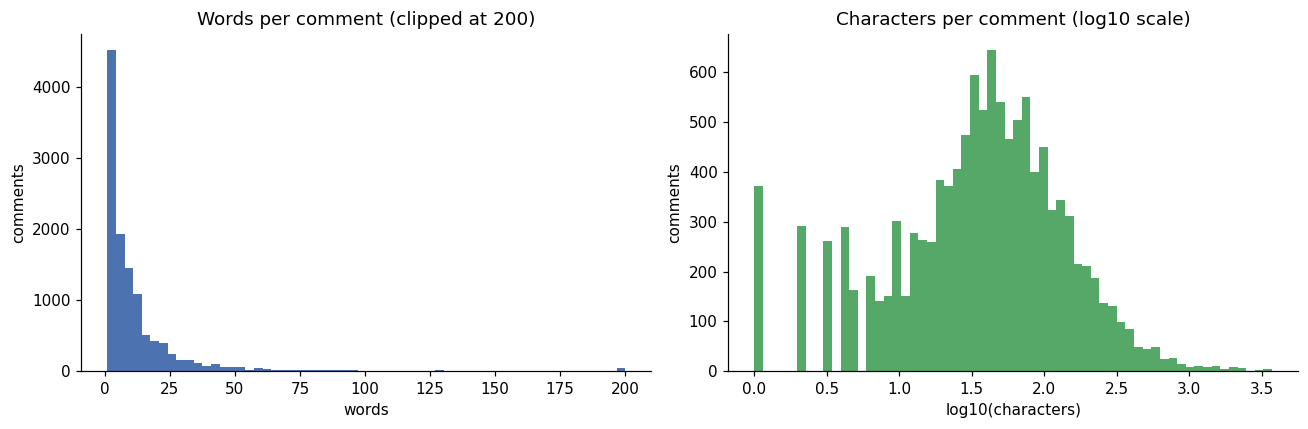

,n_words,n_chars
count,11729.0,11729.0
mean,12.8,81.0
std,25.6,164.4
min,1.0,1.0
25%,3.0,16.0
50%,6.0,40.0
75%,14.0,86.0
90%,27.0,176.0
99%,106.2,658.0
max,601.0,3717.0


Comments with <= 3 words: 3683 (31.4%)


In [128]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(corpus.n_words.clip(upper=200), bins=60, color='#4C72B0')
axes[0].set(title='Words per comment (clipped at 200)', xlabel='words', ylabel='comments')
axes[1].hist(np.log10(corpus.n_chars.clip(lower=1)), bins=60, color='#55A868')
axes[1].set(title='Characters per comment (log10 scale)', xlabel='log10(characters)', ylabel='comments')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_length_hist.png', bbox_inches='tight'); plt.show()

display(corpus[['n_words', 'n_chars']].describe(percentiles=[.25, .5, .75, .9, .99]).round(1))
print('Comments with <= 3 words:', (corpus.n_words <= 3).sum(), f'({(corpus.n_words <= 3).mean():.1%})')

In [129]:
val = (corpus[corpus.lang_group.isin(['english', 'romanised_sinhala (singlish)'])]
       .groupby('lang_group', group_keys=False)
       .apply(lambda g: g.sample(min(50, len(g)), random_state=SEED))
       [['comment_id', 'text_original', 'lang_group']])
val['human_label'] = ''
val.to_csv(BASE_DIR / 'lang_validation.csv', index=False, encoding='utf-8-sig')
print('Open lang_validation.csv in Drive, fill human_label with english / singlish, save, then run the next cell')

Open lang_validation.csv in Drive, fill human_label with english / singlish, save, then run the next cell


/tmp/ipykernel_617/3813608817.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(50, len(g)), random_state=SEED))


In [130]:
val = pd.read_csv(BASE_DIR / 'lang_validation.csv')
# Ensure human_label is treated as string and filled with a default if empty
val['human_label'] = val['human_label'].fillna('').astype(str)
val['pred'] = val.lang_group.str.startswith('romanised').map({True: 'singlish', False: 'english'})
print('Detector accuracy on 100 hand-labelled comments:', (val.pred == val.human_label.str.strip().str.lower()).mean().round(3))
pd.crosstab(val.human_label, val.pred)

Detector accuracy on 100 hand-labelled comments: 0.0


pred,english,singlish
human_label,,
,50,50


### Length by language group

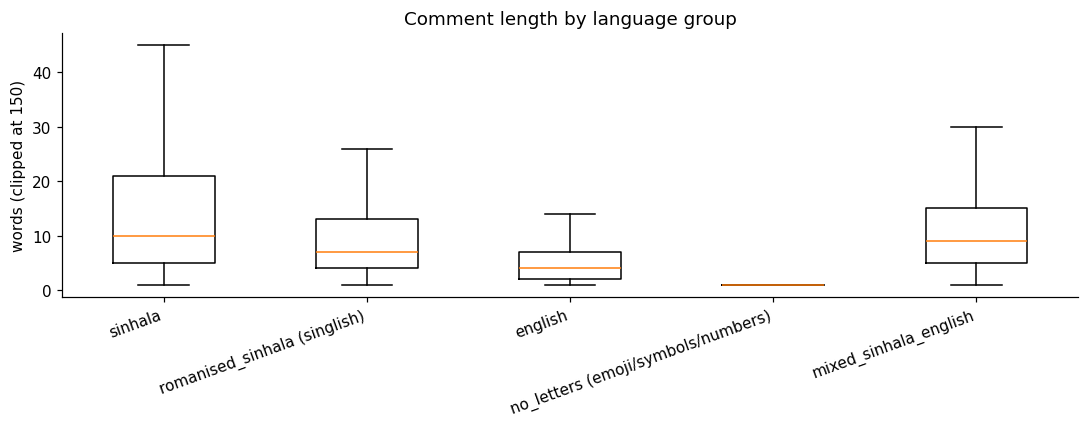

In [131]:
order = corpus.lang_group.value_counts().index
data = [corpus.loc[corpus.lang_group == g, 'n_words'].clip(upper=150) for g in order]
plt.figure(figsize=(10, 4))
plt.boxplot(data, showfliers=False)
plt.xticks(range(1, len(order) + 1), order, rotation=20, ha='right'); plt.ylabel('words (clipped at 150)')
plt.title('Comment length by language group')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_length_by_lang.png', bbox_inches='tight'); plt.show()

### Language distribution

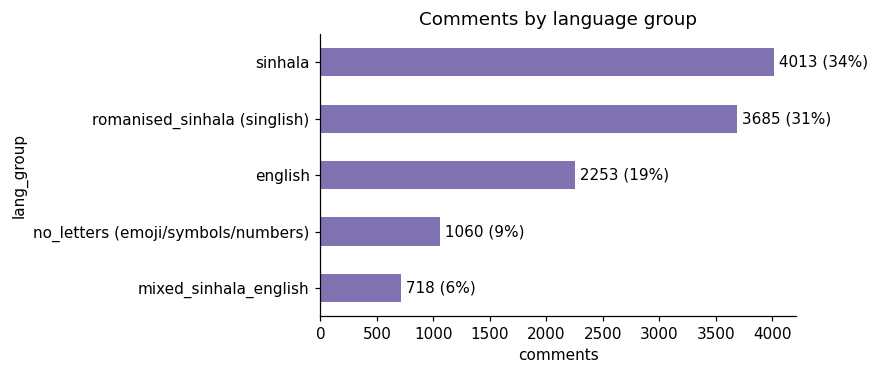

,text_original
lang_group,
english,"[Veyangoda central college is one of the best school they also have higher scholarship mark, No❤, Due to a previous ..."
mixed_sinhala_english,"[A/l private දාන්න චරිත සහතිකය ඕනෙ නැ නේද. අස්වීමෙ සහතිලය විතරක් ඇතිනේද ​@mathscrew, Hello dear... Certificate එක ex..."
no_letters (emoji/symbols/numbers),"[❤❤❤, ❤, 😮😮😮😮😮😮😢]"
romanised_sinhala (singlish),"[​@prabodhamadhurangi5190thava tikaking mata call ekak ganda kiyala denagn, Game pasala thama matanan hithena widiya..."
sinhala,"[නලින්ද එහෙන් මම කරන්න, අති විශිෂ්ටයි සහෝදරයා.❤❤❤, කවුද කියන්නේ😂]"


In [132]:
lang_counts = corpus.lang_group.value_counts()
ax = lang_counts.plot.barh(figsize=(8, 3.5), color='#8172B2')
ax.invert_yaxis(); ax.set(title='Comments by language group', xlabel='comments')
for i, v in enumerate(lang_counts):
    ax.text(v, i, f' {v} ({v/len(corpus):.0%})', va='center')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_language.png', bbox_inches='tight'); plt.show()

# sample comments per group to sanity-check the detector
corpus.groupby('lang_group').text_original.apply(
    lambda s: s.sample(min(3, len(s)), random_state=SEED).tolist()).to_frame()

### Comments per video and per channel

/tmp/ipykernel_617/2918352593.py:12: UserWarning: Glyph 119818 (\N{MATHEMATICAL BOLD CAPITAL K}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(FIG_DIR / 't1_per_video_channel.png', bbox_inches='tight'); plt.show()
/tmp/ipykernel_617/2918352593.py:12: UserWarning: Glyph 119834 (\N{MATHEMATICAL BOLD SMALL A}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(FIG_DIR / 't1_per_video_channel.png', bbox_inches='tight'); plt.show()
/tmp/ipykernel_617/2918352593.py:12: UserWarning: Glyph 119854 (\N{MATHEMATICAL BOLD SMALL U}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(FIG_DIR / 't1_per_video_channel.png', bbox_inches='tight'); plt.show()
/tmp/ipykernel_617/2918352593.py:12: UserWarning: Glyph 119852 (\N{MATHEMATICAL BOLD SMALL S}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(FIG_DIR / 't1_per_video_channel.png', bbox_inches='tight'); plt.show()
/tmp/ipykernel_617/2918352593.py:12: UserWarning: Glyph 119841

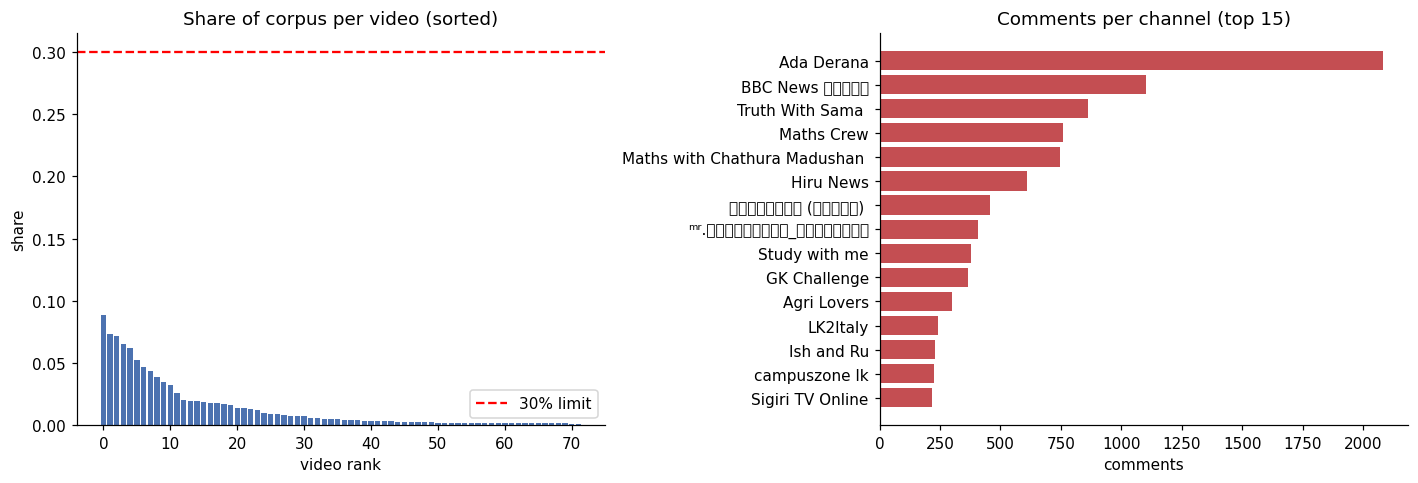

,video_id,channel_title,n,share
0,F-DLnJM7jpg,Ada Derana,1035,0.088243
1,h9nL4RwNAEE,Truth With Sama,861,0.073408
2,RHfwHM3M9Fc,Ada Derana,845,0.072044
3,1mGozsjkLYQ,Maths Crew,761,0.064882
4,-pHFRz2p-Nw,Maths with Chathura Madushan,730,0.062239
5,iKJSiiynAWQ,Hiru News,610,0.052008
6,WoD8P9g8OHs,BBC News සිංහල,552,0.047063
7,Srr-sYiIDuI,BBC News සිංහල,510,0.043482
8,j42KPskCsc0,ගුරුවරයා (කැලණි),456,0.038878
9,k7Y15uXnD_Y,ᵐʳ.𝐊𝐚𝐮𝐬𝐡𝐚𝐥𝐲𝐚_𝐎𝐟𝐟𝐢𝐜𝐢𝐚𝐥,408,0.034786


In [133]:
per_video = corpus.groupby(['video_id', 'channel_title']).size().sort_values(ascending=False).reset_index(name='n')
per_video['share'] = per_video.n / len(corpus)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(len(per_video)), per_video.share, color='#4C72B0')
axes[0].axhline(MAX_VIDEO_SHARE, ls='--', c='red', label='30% limit')
axes[0].set(title='Share of corpus per video (sorted)', xlabel='video rank', ylabel='share'); axes[0].legend()

per_channel = corpus.channel_title.value_counts().head(15)
axes[1].barh(per_channel.index[::-1], per_channel.values[::-1], color='#C44E52')
axes[1].set(title='Comments per channel (top 15)', xlabel='comments')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_per_video_channel.png', bbox_inches='tight'); plt.show()

per_video.head(10)

In [134]:
inc = videos[videos.include].sort_values('comment_count', ascending=False)
for _, v in inc.iterrows():
    sample = raw.loc[raw.video_id == v.video_id, 'text_original'].head(3).str.slice(0, 80).tolist()
    print(f"{v.video_id} | {v.channel_title} | {v.comment_count:.0f}\n   {v.title}\n   e.g. {sample}\n")

h9nL4RwNAEE | Truth With Sama  | 2497
   ශ්‍රී ලංකාවේ හොදම පාසල් 10 😱 | Top 10 best school in the srilanka #truthwithsama #top10 #viral
   e.g. ['මගේ  පාසල  කොළඹ  විශාකා  විද්\u200dයාලය ❤😂', 'මෙ සංස්කෘතිය වෙනස් කරන්න ඔනා.අවම වශයෙන් එක් දිස්ත්\u200dරික්කයට එක හොඳ ගුනාත්මක පාසලක', 'අපිට අපේ දුප්පත් ගම්වලතියෙන පාසල් ගොඩක් වට්නවා❤❤අපේ පාසල් වලට ගොඩක් ආදරෙයි ❤❤❤❤']

F-DLnJM7jpg | Ada Derana | 1030
   O/L, A/L සහ ශිෂ්‍යත්ව විභාගය ගැන දැනුම්දීමක් | Ada Derana
   e.g. ['Kimbi ammandi', 'wesagana puujita shreegabalpradha', '😂 ඔහොම හොදට ලයාන්විතව කතා කරාට මිනිහවත් බව කරන් ඇති']

RHfwHM3M9Fc | Ada Derana | 845
   අධ්‍යාපන ප්‍රතිසංස්කරණ ඇත්තටම අකුල ගත්තේ ඇයි | Ada Derana
   e.g. ['👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍❤❤❤❤❤❤❤❤❤❤', 'නලින්ද සහෝදරයා ඕවා අනිවාර්යයෙන්ම සංවාදයට ගත යුතුයි.\n❤❤❤', 'කොට කලිසම් ඇදගෙන දුවන පනින, උගුරු දණ්ඩවත් පැනලා නැත වයසකදි වෘත්තීය අධ්\u200dයාපනය තෝර']

1mGozsjkLYQ | Maths Crew | 768
   How to do AL private | Private AL Apply | උසස් පෙළ විභාගයට private app

### Language mix per channel

In [135]:
pd.crosstab(corpus.channel_title, corpus.lang_group, margins=True).sort_values('All', ascending=False).head(12)

lang_group,english,mixed_sinhala_english,no_letters (emoji/symbols/numbers),romanised_sinhala (singlish),sinhala,All
channel_title,,,,,,
All,2253,718,1060,3685,4013,11729
Ada Derana,128,135,78,740,1001,2082
BBC News සිංහල,162,46,99,170,624,1101
Truth With Sama,140,30,57,275,359,861
Maths Crew,115,85,13,438,110,761
Maths with Chathura Madushan,87,74,48,207,332,748
Hiru News,34,48,25,172,331,610
ගුරුවරයා (කැලණි),165,10,18,45,218,456
ᵐʳ.𝐊𝐚𝐮𝐬𝐡𝐚𝐥𝐲𝐚_𝐎𝐟𝐟𝐢𝐜𝐢𝐚𝐥,202,14,20,138,34,408


### Comments over time

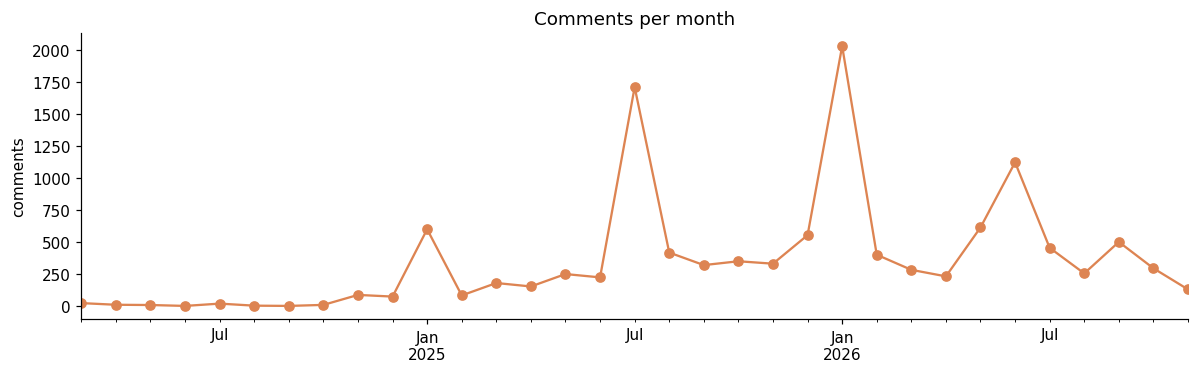

In [136]:
monthly = corpus.set_index('comment_published_at').resample('MS').size()
ax = monthly.plot(figsize=(11, 3.5), marker='o', color='#DD8452')
ax.set(title='Comments per month', xlabel='', ylabel='comments')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_timeline.png', bbox_inches='tight'); plt.show()

### Top English words and word pairs (charts)

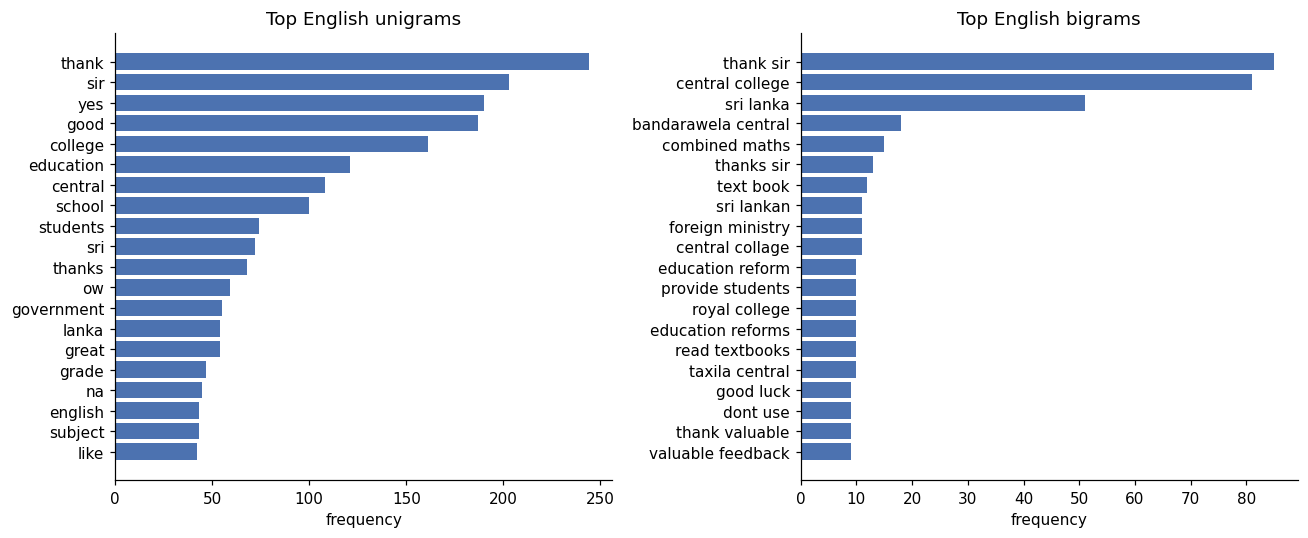

In [137]:
# EDA-only tokeniser: keeps Sinhala words whole, including vowel signs and the zero-width joiner (U+200D) in ශ්‍රී etc.
TOKEN_RE = re.compile(r"[\u0D80-\u0DFF\u200D]+|[a-z][a-z']+")
SI_STOP = {'සහ', 'හා', 'ද', 'නම්', 'ඒ', 'මේ', 'එක', 'එකක්', 'නෑ', 'නැහැ', 'කියලා', 'වගේ', 'තමයි', 'ඔයා', 'අපි', 'මම',
           'නිසා', 'තියෙන්නේ', 'ගැන', 'වෙන්න', 'කරන්න', 'එහෙම', 'මෙහෙම', 'තව', 'ඉතින්', 'හරි', 'නේ', 'ය', 'යි', 'වත්', 'දැන්'}
URL_RE = re.compile(r'https?://\S+|www\.\S+')
STOP = set(ENGLISH_STOP_WORDS) | SI_STOP | SINGLISH_MARKERS

def eda_tokens(text):
    t = URL_RE.sub(' ', str(text).lower())
    return [w for w in TOKEN_RE.findall(t) if w not in STOP and len(w) > 1]

def top_ngrams(texts, n=1, k=20):
    c = Counter()
    for t in texts:
        toks = eda_tokens(t)
        c.update(zip(*[toks[i:] for i in range(n)]))
    return pd.DataFrame([(' '.join(g), f) for g, f in c.most_common(k)], columns=['ngram', 'freq'])

groups = {'english': corpus.lang_group == 'english',
          'sinhala': corpus.lang_group == 'sinhala',
          'romanised_sinhala': corpus.lang_group.str.startswith('romanised'),
          'mixed': corpus.lang_group == 'mixed_sinhala_english'}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, n in zip(axes, (1, 2)):
    df_ng = top_ngrams(corpus.loc[groups['english'], 'text_original'], n=n)
    ax.barh(df_ng.ngram[::-1], df_ng.freq[::-1], color='#4C72B0')
    ax.set(title=f'Top English {"unigrams" if n == 1 else "bigrams"}', xlabel='frequency')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_english_ngrams.png', bbox_inches='tight'); plt.show()

### Top Sinhala / Singlish / mixed words (tables, because charts can't draw Sinhala letters properly)

In [138]:
tables = []
for g in ['sinhala', 'romanised_sinhala', 'mixed']:
    if groups[g].sum() == 0:
        continue
    for n in (1, 2):
        t = top_ngrams(corpus.loc[groups[g], 'text_original'], n=n, k=15)
        t.columns = pd.MultiIndex.from_product([[f'{g} {"uni" if n == 1 else "bi"}gram'], t.columns])
        tables.append(t)
pd.concat(tables, axis=1)

sinhala unigram               sinhala bigram       \
             ngram freq                   ngram freq   
0             ගන්න  294                ජයම වේවා  166   
1             නැති  278              බුදු සරණයි  164   
2              කරන  273               වේවා බුදු  162   
3               ඒක  267            සරණයි ආදරෙයි  162   
4            පාසල්  264               ඉගෙන ගන්න   67   
5             ඉන්න  263  අධ්‍යාපන ප්‍රතිසංස්කරණ   46   
6         අධ්‍යාපන  248                උසස් පෙළ   38   
7             වේවා  241                පාසල් වල   34   
8               ඕන  234                හීන හැබෑ   31   
9              අපේ  233               හැබෑ වේවා   31   
10             වලට  231            වේවා සතුටින්   31   
11              ඔය  229      සතුටින් පරිස්සමෙන්   31   
12             එපා  227         පරිස්සමෙන් ඉන්න   31   
13              වල  227                ඉන්න ජයම   31   
14             මේක  222                 අපේ රටේ   30   

   romanised_sinhala unigram      romanised_sinhala bigram      mixed unigram  \
                       ngram freq                    ngram freq         ngram   
0                         na  347         foreign ministry   63           එකට   
1                    private  136         reference number   31           එකේ   
2                        sir  130            kisima rataka   30          ගන්න   
3                      apply  129              links danne   29       private   
4                       exam  125            mulinma buddy   28         maths   
5                         ek  125                buddy net   28            ඒක   
6                certificate  117            thoge mulinma   27           වලට   
7                         ne  115               net deepan   27           shy   
8                     school  113              deepan moda   27      syllabus   
9                        ane  112              moda haraka   27       english   
10                       oni  112             haraka links   27          කරලා   
11                       shy   97             danne kisima   27         දාන්න   
12                        mn   97           rataka thopita   27            මට   
13                      hari   96            thopita pissu   27           කරන   
14                       dan   93              pissu unata   27          exam   

               mixed bigram       
   freq               ngram freq  
0    59      english medium   11  
1    46    foreign ministry   10  
2    43            exam එකට    9  
3    43              nd shy    9  
4    42  maths withchathura    8  
5    42      අලුත් syllabus    8  
6    37              st shy    8  
7    37       private apply    7  
8    35      combined maths    7  
9    35       private දාන්න    6  
10   35              rd shy    6  
11   35        result sheet    6  
12   33     central college    6  
13   32          second shy    5  
14   31          al private    5